In [1]:
from google.colab import drive
drive.mount('/content/drive')

import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
!nvidia-smi

Mounted at /content/drive
PyTorch: 2.11.0+cu130
GPU available: True
Wed Oct 28 22:03:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             15W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |    

In [2]:
import torch
from torch.utils.data import DataLoader, ConcatDataset, Subset
from torchvision import datasets, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# ImageNet mean/std (pretrained models isi pe train hue hain)
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

# Training transforms (augmentation ke saath)
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Validation/Test transforms (augmentation nahi, sirf resize)
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Teeno official splits ko mila do (1020 + 1020 + 6149 = 8189)
def load_all(tf):
    parts = [datasets.Flowers102(root="data", split=s, transform=tf, download=True)
             for s in ["train", "val", "test"]]
    return ConcatDataset(parts)

full_train = load_all(train_tf)   # augmentation wala
full_eval  = load_all(eval_tf)    # bina augmentation

# 70/15/15 split (seed fix hai taake har baar same split mile)
n = len(full_train)
g = torch.Generator().manual_seed(42)
idx = torch.randperm(n, generator=g).tolist()
n_train, n_val = int(0.70 * n), int(0.15 * n)

train_idx = idx[:n_train]
val_idx   = idx[n_train:n_train + n_val]
test_idx  = idx[n_train + n_val:]

train_ds = Subset(full_train, train_idx)
val_ds   = Subset(full_eval,  val_idx)
test_ds  = Subset(full_eval,  test_idx)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2)

print("Train/Val/Test:", len(train_ds), len(val_ds), len(test_ds))

# Quick check
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)   # [32, 3, 224, 224]
print("Labels:", labels[:10])

Device: cuda


100%|██████████| 345M/345M [00:14<00:00, 24.0MB/s]
100%|██████████| 502/502 [00:00<00:00, 969kB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 34.0MB/s]


Train/Val/Test: 5732 1228 1229
Batch shape: torch.Size([32, 3, 224, 224])
Labels: tensor([96, 89, 50,  6, 88, 63, 34, 76, 76, 83])


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 59.8MB/s]


Epoch 1/10 | train loss 1.764 acc 0.634 | val loss 0.488 acc 0.902
Epoch 2/10 | train loss 0.357 acc 0.928 | val loss 0.283 acc 0.931
Epoch 3/10 | train loss 0.188 acc 0.965 | val loss 0.204 acc 0.952
Epoch 4/10 | train loss 0.094 acc 0.983 | val loss 0.159 acc 0.959
Epoch 5/10 | train loss 0.061 acc 0.990 | val loss 0.140 acc 0.968
Epoch 6/10 | train loss 0.034 acc 0.995 | val loss 0.114 acc 0.974
Epoch 7/10 | train loss 0.025 acc 0.997 | val loss 0.114 acc 0.976
Epoch 8/10 | train loss 0.016 acc 0.999 | val loss 0.105 acc 0.976
Epoch 9/10 | train loss 0.014 acc 0.999 | val loss 0.106 acc 0.976
Epoch 10/10 | train loss 0.013 acc 0.999 | val loss 0.107 acc 0.976
Training time: 8.4 min
TEST accuracy: 0.9772 | macro F1: 0.9725


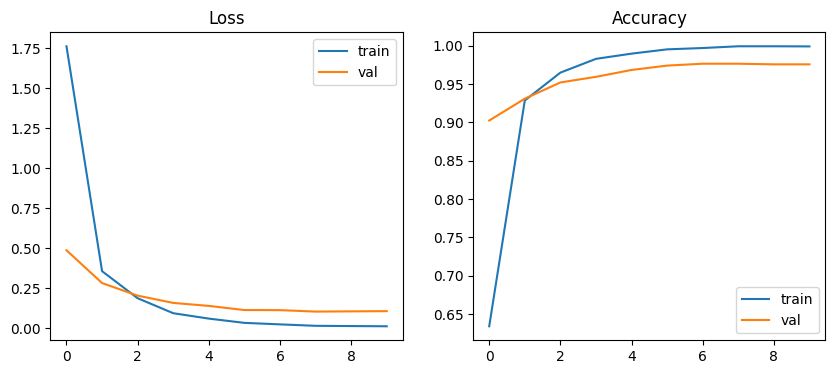

In [3]:
import torch, torch.nn as nn, time, copy
import matplotlib.pyplot as plt
from torchvision import models
from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 10

# 1) Pretrained MobileNetV2, last layer ko 102 classes ke liye badlo
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.last_channel, 102)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, preds, targets = 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            preds += out.argmax(1).cpu().tolist()
            targets += y.cpu().tolist()
    return total_loss / len(loader.dataset), accuracy_score(targets, preds), preds, targets

# 2) Training loop (best val accuracy wala model save hota hai)
history = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": []}
best_acc, best_state = 0, None
start = time.time()
for ep in range(EPOCHS):
    tl, ta, _, _ = run_epoch(train_loader, True)
    vl, va, _, _ = run_epoch(val_loader, False)
    scheduler.step()
    for k, v in zip(history, [tl, vl, ta, va]): history[k].append(v)
    if va > best_acc:
        best_acc, best_state = va, copy.deepcopy(model.state_dict())
    print(f"Epoch {ep+1}/{EPOCHS} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
print(f"Training time: {(time.time()-start)/60:.1f} min")

# 3) Test evaluation
model.load_state_dict(best_state)
_, test_acc, p, t = run_epoch(test_loader, False)
print(f"TEST accuracy: {test_acc:.4f} | macro F1: {f1_score(t, p, average='macro'):.4f}")

# 4) Curves (report ke liye)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(history["tr_loss"], label="train"); ax[0].plot(history["va_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["tr_acc"], label="train"); ax[1].plot(history["va_acc"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.savefig("curves.png", dpi=150); plt.show()

# 5) Weights save karo
torch.save(best_state, "best_model.pth")

In [4]:
!mkdir -p /content/drive/MyDrive/flower_project
!cp best_model.pth curves.png /content/drive/MyDrive/flower_project/
!ls -lh /content/drive/MyDrive/flower_project

total 9.3M
-rw------- 1 root root 9.3M Oct 28 22:20 best_model.pth
-rw------- 1 root root  55K Oct 28 22:20 curves.png


In [8]:
!pip install -q onnx onnxruntime

import json, os, numpy as np, onnxruntime as ort

# 1) Best weights load karke CPU par eval mode mein lao
model.load_state_dict(torch.load("best_model.pth", map_location="cpu"))
model = model.cpu().eval()

# 2) ONNX export (dynamo=False taake sirf ek single file bane)
dummy = torch.randn(1, 3, 224, 224)
torch.onnx.export(model, dummy, "model.onnx",
                  input_names=["input"], output_names=["output"],
                  opset_version=17, dynamo=False)

print("Files:", [f for f in os.listdir(".") if f.startswith("model.onnx")])
print("Size (MB):", round(os.path.getsize("model.onnx")/1e6, 1))

# 3) Check: ONNX output PyTorch ke barabar hai?
sess = ort.InferenceSession("model.onnx")
x = images[:4].cpu()          # Step 2 ka batch
with torch.no_grad():
    pt_out = model(x).numpy()
onnx_out = np.concatenate([sess.run(None, {"input": x[i:i+1].numpy()})[0] for i in range(4)])
print("Max difference:", np.abs(pt_out - onnx_out).max())
print("Predictions match:", (pt_out.argmax(1) == onnx_out.argmax(1)).all())

# 4) 102 class names (index 0 = category 1, torchvision ke labels ke mutabiq)
class_names = [
 "pink primrose","hard-leaved pocket orchid","canterbury bells","sweet pea","english marigold",
 "tiger lily","moon orchid","bird of paradise","monkshood","globe thistle",
 "snapdragon","colt's foot","king protea","spear thistle","yellow iris",
 "globe-flower","purple coneflower","peruvian lily","balloon flower","giant white arum lily",
 "fire lily","pincushion flower","fritillary","red ginger","grape hyacinth",
 "corn poppy","prince of wales feathers","stemless gentian","artichoke","sweet william",
 "carnation","garden phlox","love in the mist","mexican aster","alpine sea holly",
 "ruby-lipped cattleya","cape flower","great masterwort","siam tulip","lenten rose",
 "barbeton daisy","daffodil","sword lily","poinsettia","bolero deep blue",
 "wallflower","marigold","buttercup","oxeye daisy","common dandelion",
 "petunia","wild pansy","primula","sunflower","pelargonium",
 "bishop of llandaff","gaura","geranium","orange dahlia","pink-yellow dahlia",
 "cautleya spicata","japanese anemone","black-eyed susan","silverbush","californian poppy",
 "osteospermum","spring crocus","bearded iris","windflower","tree poppy",
 "gazania","azalea","water lily","rose","thorn apple",
 "morning glory","passion flower","lotus","toad lily","anthurium",
 "frangipani","clematis","hibiscus","columbine","desert-rose",
 "tree mallow","magnolia","cyclamen","watercress","canna lily",
 "hippeastrum","bee balm","ball moss","foxglove","bougainvillea",
 "camellia","mallow","mexican petunia","bromelia","blanket flower",
 "trumpet creeper","blackberry lily"
]
print("Total classes:", len(class_names))   # 102 hona chahiye
with open("class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

/tmp/ipykernel_666/1325043830.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, "model.onnx",


Files: ['model.onnx']
Size (MB): 9.4
Max difference: 9.587035e-06
Predictions match: True
Total classes: 102


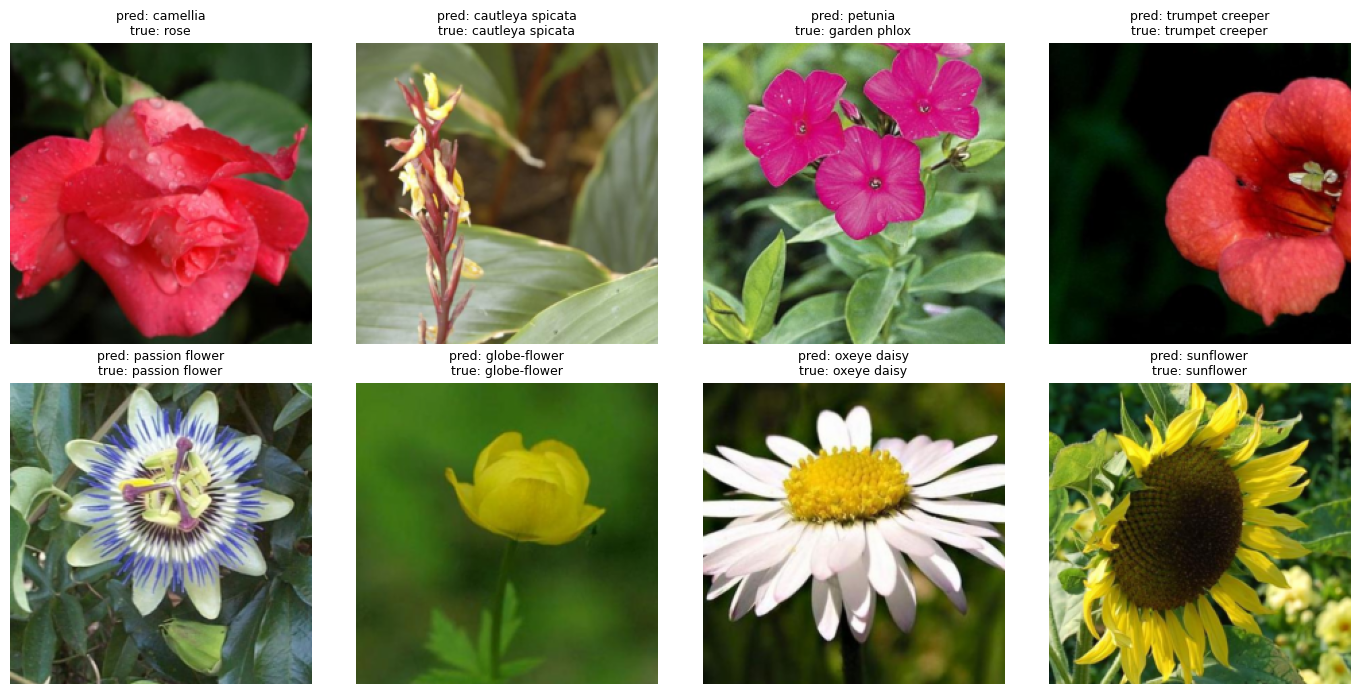

In [11]:
import matplotlib.pyplot as plt
model_gpu = model.to(device).eval()
imgs, lbls = next(iter(test_loader))
with torch.no_grad():
    preds = model_gpu(imgs.to(device)).argmax(1).cpu()

mean_t = torch.tensor(mean).view(3,1,1); std_t = torch.tensor(std).view(3,1,1)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, im, pr, tr in zip(axes.flat, imgs[:8], preds[:8], lbls[:8]):
    ax.imshow((im*std_t + mean_t).permute(1,2,0).clamp(0,1))
    ax.set_title(f"pred: {class_names[pr]}\ntrue: {class_names[tr]}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.savefig("sample_predictions.png", dpi=150); plt.show()

In [12]:
import numpy as np
from collections import Counter

model_gpu = model.to(device).eval()
all_p, all_t = [], []
with torch.no_grad():
    for x, y in test_loader:
        all_p += model_gpu(x.to(device)).argmax(1).cpu().tolist()
        all_t += y.tolist()
all_p, all_t = np.array(all_p), np.array(all_t)

print("Test accuracy:", round((all_p == all_t).mean(), 4))
wrong = np.where(all_p != all_t)[0]
print("Wrong:", len(wrong), "of", len(all_t))

pairs = Counter((class_names[t], class_names[p]) for t, p in zip(all_t[wrong], all_p[wrong]))
for (t, p), c in pairs.most_common(8):
    print(f"true: {t}  ->  predicted: {p}  ({c}x)")

Test accuracy: 0.9772
Wrong: 28 of 1229
true: petunia  ->  predicted: tree mallow  (2x)
true: rose  ->  predicted: camellia  (1x)
true: garden phlox  ->  predicted: petunia  (1x)
true: prince of wales feathers  ->  predicted: carnation  (1x)
true: tree poppy  ->  predicted: windflower  (1x)
true: sword lily  ->  predicted: canna lily  (1x)
true: sword lily  ->  predicted: cyclamen  (1x)
true: japanese anemone  ->  predicted: tree poppy  (1x)


In [13]:
!cp model.onnx class_names.json sample_predictions.png /content/drive/MyDrive/flower_project/

from google.colab import files
for f in ["model.onnx", "class_names.json", "best_model.pth", "curves.png", "sample_predictions.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>